In [1]:
import torch
from GAN.src.model import build_res_unet, MainModel
from GAN.src.visualize import visualize_gan
from CNN.src.visualize import visualize_cnn
from CNN.src.model import build_colorization_model
from src.evaluate import avg_deltaE, mean_chroma, mse
from src.visualize import visualize
from prettytable import PrettyTable

/Users/alassanediagne/miniconda3/envs/3dcv-students/lib/python3.10/site-packages/scipy/__init__.py:155: UserWarning: A NumPy version >=1.18.5 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
2025-04-02 17:47:50.995018: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load models

In [10]:
# CNN
# Define image size
img_size = 256

# Create the model
cnn = build_colorization_model(input_shape=(img_size, img_size, 1))

# Load weights from the .h5 file
cnn.load_weights("CNN/checkpoints/colorization-faces-unet-0.009.h5")

In [5]:
# cGANs
# load generators
net_G1 = build_res_unet(n_input=1, n_output=2, size=256)
net_G1.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

net_G2 = build_res_unet(n_input=1, n_output=2, size=256)
net_G2.load_state_dict(torch.load("GAN/src/checkpoints/res18-unet.pt", map_location=device))

<All keys matched successfully>

In [6]:
# base model
gan1 = MainModel(net_G = net_G1)
gan1.load_state_dict(torch.load("GAN/src/checkpoints/final_model_weights.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

In [7]:
# finetuned model
gan2 = MainModel(net_G = net_G2)
gan2.load_state_dict(torch.load("GAN/src/checkpoints/fine_tuned_faces.pt", map_location=device))

model initialized with norm initialization


<All keys matched successfully>

# Visualizations

1/1 [==============================] - 0s 394ms/step


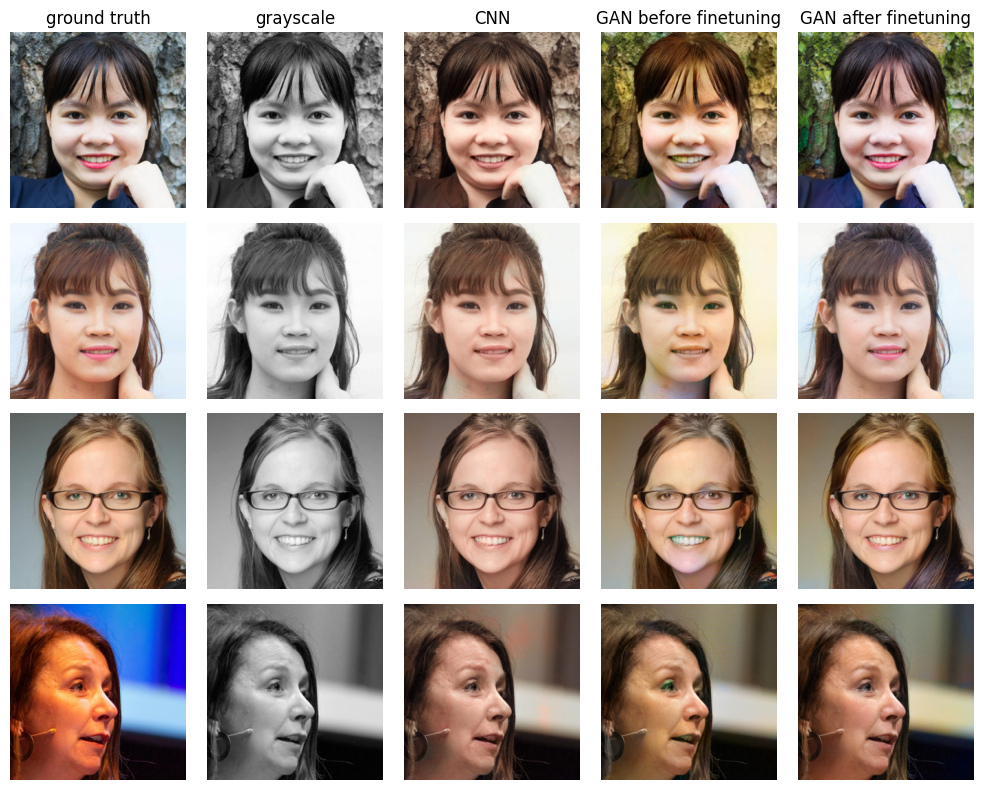

In [9]:
visualize(cnn,gan1,gan2,"data/faces_val", seed = 13)

# Evaluation

In [ ]:
# CIEDE2000 Delta E score
cnn_deltae = avg_deltaE(cnn, "data/faces_val", model_type="CNN", seed = 13, size = 50)
gan1_deltae = avg_deltaE(gan1, "data/faces_val", model_type="GAN", seed = 13, size = 10)
gan2_deltae = avg_deltaE(gan2, "data/faces_val", model_type="GAN", seed = 13, size = 10)

evaluating GAN:   0%|          | 0/10 [00:00<?, ?it/s]

evaluating GAN: 100%|██████████| 10/10 [00:11<00:00,  1.12s/it]


In [ ]:
# mean average chroma
cnn_chroma = mean_chroma(cnn, "data/faces_val", model_type="CNN", seed = 13, size = 50)
gan1_chroma = mean_chroma(gan1, "data/faces_val", model_type="GAN", seed = 13, size = 50)
gan2_chroma = mean_chroma(gan2, "data/faces_val", model_type="GAN", seed = 13, size = 50)

In [ ]:
# mean squared error
cnn_mse = mse(cnn, "data/faces_val", model_type="CNN", seed = 13, size = 50)
gan1_mse = mse(gan1, "data/faces_val", model_type="GAN", seed = 13, size = 50)
gan2_mse = mse(gan2, "data/faces_val", model_type="GAN", seed = 13, size = 50)

In [ ]:
evals = PrettyTable()
evals.field_names = ["metric", "CNN", "base GAN", "finetuned GAN"]
evals.add_row(["CIDE 2000 Delta E", cnn_deltae, gan1_deltae, gan2_deltae])
evals.add_row(["mean average chroma", cnn_chroma, gan1_chroma, gan2_chroma])
evals.add_row(["MSE", cnn_mse, gan1_mse, gan2_mse])
print(evals)

+---------------------+-----+----------+---------------+
|        metric       | CNN | base GAN | finetuned GAN |
+---------------------+-----+----------+---------------+
|  CIDE 2000 Delta E  |  0  |    0     |       0       |
| mean average chroma |  0  |    0     |       0       |
|         MSE         |  0  |    0     |       0       |
+---------------------+-----+----------+---------------+
